# 05 — Hybrid Fusion and Reranking

This notebook combines the results from multiple retrieval strategies and improves
the final ranking using hybrid fusion and cross-encoder reranking.

### Pipeline

Query
→ Naive Retrieval
→ Sentence Window Retrieval
→ Parent-Child Retrieval
→ Candidate Fusion
→ Reciprocal Rank Fusion (RRF)
→ Cross-Encoder Reranking
→ Final Top-K Context

## Objective

The retrieval stage generates candidate documents using multiple retrieval
strategies. Each strategy captures different aspects of relevance.

In this notebook, we will:

1. Collect retrieval results from the three retrieval strategies.
2. Remove duplicate candidates.
3. Combine the rankings using Reciprocal Rank Fusion (RRF).
4. Apply a cross-encoder reranker to the fused candidates.
5. Compare the rankings before and after reranking.
6. Prepare the final context that will be passed to the generation stage.

In [2]:
import numpy as np
import pandas as pd
from collections import defaultdict

from sentence_transformers import CrossEncoder

print("Imports successful")

c:\Users\Dell\anaconda3\envs\asl_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports successful


In [3]:
import sys

print("Python:", sys.version)
print("Python executable:", sys.executable)

Python: 3.10.18 | packaged by Anaconda, Inc. | (main, Jun  5 2025, 13:08:55) [MSC v.1929 64 bit (AMD64)]
Python executable: c:\Users\Dell\anaconda3\envs\asl_env\python.exe


In [4]:
%pip install pandas numpy sentence-transformers

Note: you may need to restart the kernel to use updated packages.


In [5]:
RERANKER_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"

reranker = CrossEncoder(RERANKER_MODEL)

print(f"Reranker loaded: {RERANKER_MODEL}")

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 1009.76it/s]


Reranker loaded: cross-encoder/ms-marco-MiniLM-L-6-v2


In [6]:
# Number of candidates retrieved from each retrieval strategy
RETRIEVAL_TOP_K = 5

# Number of candidates retained after hybrid fusion
FUSION_TOP_K = 15

# Number of final documents passed to the generation stage
FINAL_TOP_K = 5

# RRF constant
RRF_K = 60

print("Configuration loaded")
print(f"Retrieval Top-K : {RETRIEVAL_TOP_K}")
print(f"Fusion Top-K    : {FUSION_TOP_K}")
print(f"Final Top-K     : {FINAL_TOP_K}")
print(f"RRF K           : {RRF_K}")

Configuration loaded
Retrieval Top-K : 5
Fusion Top-K    : 15
Final Top-K     : 5
RRF K           : 60


In [7]:
RETRIEVAL_SOURCES = [
    "naive",
    "sentence_window",
    "parent_child"
]

print("Retrieval strategies:")
for source in RETRIEVAL_SOURCES:
    print(f"- {source}")

Retrieval strategies:
- naive
- sentence_window
- parent_child


In [8]:
def create_retrieval_result(
    text,
    score,
    rank,
    source,
    metadata=None
):
    return {
        "text": text,
        "score": float(score),
        "rank": int(rank),
        "source": source,
        "metadata": metadata or {}
    }

print("Retrieval result structure defined")

Retrieval result structure defined


In [9]:
RERANKER_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"

reranker = CrossEncoder(RERANKER_MODEL)

print(f"Reranker loaded: {RERANKER_MODEL}")

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 985.10it/s]


Reranker loaded: cross-encoder/ms-marco-MiniLM-L-6-v2


In [10]:
test_query = "Who is eligible for PMAY-U?"

test_documents = [
    "PMAY-U provides housing assistance to eligible beneficiaries.",
    "The scheme is intended for eligible urban households who meet the prescribed criteria.",
    "The application process requires submission of the necessary documents."
]

pairs = [(test_query, doc) for doc in test_documents]

scores = reranker.predict(pairs)

for i, score in enumerate(scores):
    print(f"{i + 1}. Score: {score:.4f}")
    print(f"   {test_documents[i]}")
    print()

1. Score: 6.0256
   PMAY-U provides housing assistance to eligible beneficiaries.

2. Score: -5.6649
   The scheme is intended for eligible urban households who meet the prescribed criteria.

3. Score: -11.0592
   The application process requires submission of the necessary documents.



In [11]:
def rerank_documents(query, documents, top_k=5):
    """
    Rerank documents using the Cross-Encoder.
    """

    if not documents:
        return []

    pairs = [
        (query, document["text"])
        for document in documents
    ]

    scores = reranker.predict(pairs)

    reranked = []

    for document, score in zip(documents, scores):
        result = document.copy()
        result["rerank_score"] = float(score)
        reranked.append(result)

    reranked.sort(
        key=lambda x: x["rerank_score"],
        reverse=True
    )

    return reranked[:top_k]


print("Reranking function defined")

Reranking function defined


In [12]:
def build_candidate_pool(*retrieval_results):
    """
    Combine retrieval results from multiple retrieval strategies
    into a single candidate pool.
    """

    candidate_pool = []

    for results in retrieval_results:
        if results:
            candidate_pool.extend(results)

    return candidate_pool


print("Candidate pool function defined")

Candidate pool function defined


In [13]:
def deduplicate_documents(documents):
    """
    Remove duplicate documents based on their text content.
    """

    unique_documents = {}
    
    for document in documents:
        text = document["text"].strip()

        if text not in unique_documents:
            unique_documents[text] = document

    return list(unique_documents.values())


print("Deduplication function defined")

Deduplication function defined


In [14]:
def reciprocal_rank_fusion(retrieval_results, k=60):
    """
    Combine rankings from multiple retrieval strategies using
    Reciprocal Rank Fusion (RRF).

    RRF Score = sum(1 / (k + rank))
    """

    rrf_scores = defaultdict(float)
    document_map = {}

    for results in retrieval_results:
        for rank, document in enumerate(results, start=1):

            text = document["text"].strip()

            # Store the document
            if text not in document_map:
                document_map[text] = document.copy()

            # Add RRF contribution
            rrf_scores[text] += 1 / (k + rank)

    # Create fused results
    fused_results = []

    for text, score in rrf_scores.items():
        result = document_map[text].copy()
        result["rrf_score"] = score
        fused_results.append(result)

    # Sort by RRF score
    fused_results.sort(
        key=lambda x: x["rrf_score"],
        reverse=True
    )

    return fused_results


print("RRF function defined")

RRF function defined


In [15]:
def hybrid_fusion(*retrieval_results, top_k=10, rrf_k=60):
    """
    Combine multiple retrieval strategies using:
    Candidate Pool → Deduplication → RRF
    """

    # Combine all retrieval results
    candidate_pool = build_candidate_pool(*retrieval_results)

    # Remove duplicates
    candidate_pool = deduplicate_documents(candidate_pool)

    # Apply Reciprocal Rank Fusion
    fused_results = reciprocal_rank_fusion(
        retrieval_results,
        k=rrf_k
    )

    # Keep top-k candidates
    return fused_results[:top_k]


print("Hybrid fusion function defined")

Hybrid fusion function defined


In [16]:
def standardize_results(results, source):
    """
    Convert retrieval results into the common retrieval-result structure.
    """

    standardized = []

    for rank, result in enumerate(results, start=1):
        if isinstance(result, dict):
            text = result.get("text", "")
            score = result.get("score", 0.0)
            metadata = result.get("metadata", {})
        else:
            text = str(result)
            score = 0.0
            metadata = {}

        standardized.append(
            create_retrieval_result(
                text=text,
                score=score,
                rank=rank,
                source=source,
                metadata=metadata
            )
        )

    return standardized


print("Result standardization function defined")

Result standardization function defined


In [17]:
def display_results(results, title="Results"):
    """
    Display retrieval results in a readable format.
    """

    print("=" * 80)
    print(title)
    print("=" * 80)

    if not results:
        print("No results found.")
        return

    for i, result in enumerate(results, start=1):
        print(f"\nRank {i}")

        if "rrf_score" in result:
            print(f"RRF Score     : {result['rrf_score']:.6f}")

        if "rerank_score" in result:
            print(f"Rerank Score  : {result['rerank_score']:.6f}")

        if "score" in result:
            print(f"Original Score: {result['score']:.6f}")

        print(f"Source        : {result.get('source', 'N/A')}")
        print(f"Text          : {result['text'][:500]}")

    print("\n" + "=" * 80)


print("Display function defined")

Display function defined


In [18]:
# Display variables currently available in the notebook
variables = [
    name for name in globals()
    if not name.startswith("_")
]

print("Available variables:")
for name in sorted(variables):
    print("-", name)

Available variables:
- CrossEncoder
- FINAL_TOP_K
- FUSION_TOP_K
- In
- Out
- RERANKER_MODEL
- RETRIEVAL_SOURCES
- RETRIEVAL_TOP_K
- RRF_K
- build_candidate_pool
- create_retrieval_result
- deduplicate_documents
- defaultdict
- display_results
- exit
- found
- get_ipython
- hybrid_fusion
- i
- np
- open
- pairs
- pd
- quit
- reciprocal_rank_fusion
- rerank_documents
- reranker
- score
- scores
- section
- source
- standardize_results
- sys
- target_sections
- test_documents
- test_query


In [19]:
QUERY = "Who is eligible for PMAY-U?"

TOP_K = 5

print("Query:", QUERY)
print("Top-K:", TOP_K)

Query: Who is eligible for PMAY-U?
Top-K: 5


In [20]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Current working directory:
d:\Sem VII\AI\Project\Implementation\Hybrid-RAG-Project\notebooks

Files/folders here:
['01_setup.ipynb', '02_document_processing.ipynb', '03_embeddings_and_vector_store.ipynb', '04_retrieval.ipynb', '05_hybrid_fusion_and_reranking.ipynb']


In [21]:
from pathlib import Path

current_dir = Path.cwd()
project_dir = current_dir.parent

print("Project directory:")
print(project_dir)

print("\nProject contents:")
for item in project_dir.iterdir():
    print(item.name)

Project directory:
d:\Sem VII\AI\Project\Implementation\Hybrid-RAG-Project

Project contents:
.git
.gitignore
app
data
evaluation
notebooks
processed
README.md
requirements.txt
src


In [22]:
import faiss
import pickle
from pathlib import Path

VECTOR_STORE_DIR = Path("../data/vector_store")

print("Vector store exists:", VECTOR_STORE_DIR.exists())
print("Vector store path:", VECTOR_STORE_DIR.resolve())

Vector store exists: True
Vector store path: D:\Sem VII\AI\Project\Implementation\Hybrid-RAG-Project\data\vector_store


In [23]:
# Load FAISS indexes

naive_index = faiss.read_index(
    str(VECTOR_STORE_DIR / "naive_rag.index")
)

sentence_window_index = faiss.read_index(
    str(VECTOR_STORE_DIR / "sentence_window.index")
)

parent_child_index = faiss.read_index(
    str(VECTOR_STORE_DIR / "parent_child.index")
)

print("Vector stores loaded successfully")
print()
print("Naive RAG index       :", naive_index.ntotal)
print("Sentence Window index :", sentence_window_index.ntotal)
print("Parent-Child index    :", parent_child_index.ntotal)

Vector stores loaded successfully

Naive RAG index       : 5
Sentence Window index : 105
Parent-Child index    : 38


In [24]:
# Load metadata

with open(VECTOR_STORE_DIR / "naive_rag_metadata.pkl", "rb") as f:
    naive_metadata = pickle.load(f)

with open(VECTOR_STORE_DIR / "sentence_window_metadata.pkl", "rb") as f:
    sentence_window_metadata = pickle.load(f)

with open(VECTOR_STORE_DIR / "parent_child_metadata.pkl", "rb") as f:
    parent_child_metadata = pickle.load(f)

print("Metadata loaded successfully")
print()
print("Naive RAG metadata       :", len(naive_metadata))
print("Sentence Window metadata :", len(sentence_window_metadata))
print("Parent-Child metadata    :", len(parent_child_metadata))

Metadata loaded successfully

Naive RAG metadata       : 5
Sentence Window metadata : 105
Parent-Child metadata    : 38


In [25]:
print("Embedding model available:", "embedding_model" in globals())

Embedding model available: False


In [26]:
print("Sample Naive RAG metadata:")
print(naive_metadata[0])

Sample Naive RAG metadata:
{'chunk_id': 'naive_0', 'scheme': 'Pradhan Mantri Awas Yojana - Urban', 'section': 'details', 'text': 'Pradhan Mantri Awas Yojana - Urban (PMAY-U) is a scheme of the Ministry of Housing & Urban Affairs (MoHUA), Government of India.\n\nThe scheme was launched to address the urban housing shortage among economically weaker sections (EWS), low income groups (LIG), middle income groups (MIG), including slum dwellers, by ensuring a pucca house to eligible urban households.\n\nThe scheme covers statutory towns as per Census 2011 and towns subsequently notified. It also provides support for affordable housing and improvement of housing conditions in urban areas.\n\nThe scheme includes provisions related to slum rehabilitation, affordable housing, credit linked subsidy and beneficiary-led individual house construction or enhancement.\n\nAadhaar or Virtual ID may be required for beneficiaries under the scheme.\n\nThe mission aims to provide affordable and adequate hou

In [27]:
from sentence_transformers import SentenceTransformer

MODEL_NAME = "all-MiniLM-L6-v2"

print("Loading embedding model...")
print("Model:", MODEL_NAME)

embedding_model = SentenceTransformer(MODEL_NAME)

print("\nEmbedding model loaded successfully!")
print("Device:", embedding_model.device)

Loading embedding model...
Model: all-MiniLM-L6-v2


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 909.48it/s]



Embedding model loaded successfully!
Device: cpu


In [28]:
def retrieve_naive(query, top_k=5):
    """
    Retrieve top-k documents from the Naive RAG FAISS index.
    """

    # Generate query embedding
    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding,
        dtype="float32"
    )

    # Search FAISS
    scores, indices = naive_index.search(
        query_embedding,
        top_k
    )

    results = []

    for rank, (score, idx) in enumerate(
        zip(scores[0], indices[0]),
        start=1
    ):
        if idx == -1:
            continue

        metadata = naive_metadata[idx]

        results.append(
            create_retrieval_result(
                text=metadata["text"],
                score=score,
                rank=rank,
                source="naive",
                metadata=metadata
            )
        )

    return results


print("Naive retrieval function defined")

Naive retrieval function defined


In [29]:
QUERY = "Who is eligible for PMAY-U?"

naive_results = retrieve_naive(
    QUERY,
    top_k=RETRIEVAL_TOP_K
)

display_results(
    naive_results,
    title="Naive RAG Results"
)

Naive RAG Results

Rank 1
Original Score: 0.696832
Source        : naive
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

2. Applications may be submitted through the online system or through the concerned Urban Local Body (ULB) or other designated agencies.

3. The applicant must provide the required personal, family, income and other details along with the necessary documents.

4. The application is verified by the concerned authorities before the beneficiary is considered for assistance under th

Rank 2
Original Score: 0.553095
Source        : naive
Text          : Pradhan Mantri Awas Yojana - Urban (PMAY-U) is a scheme of the Ministry of Housing & Urban Affairs (MoHUA), Government of India.

The scheme was launched to address the urban housing shortage among economically weaker sections (EWS), low income groups (LIG), middle income groups (MIG), including slum dwellers, by ensuring a pucca house t

In [30]:
def retrieve_sentence_window(query, top_k=5):
    """
    Retrieve top-k results from the Sentence Window FAISS index.
    """

    # Generate query embedding
    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding,
        dtype="float32"
    )

    # Search FAISS
    scores, indices = sentence_window_index.search(
        query_embedding,
        top_k
    )

    results = []

    for rank, (score, idx) in enumerate(
        zip(scores[0], indices[0]),
        start=1
    ):
        if idx == -1:
            continue

        metadata = sentence_window_metadata[idx]

        # Sentence-window text
        text = metadata.get(
            "window_text",
            metadata.get("text", "")
        )

        results.append(
            create_retrieval_result(
                text=text,
                score=score,
                rank=rank,
                source="sentence_window",
                metadata=metadata
            )
        )

    return results


print("Sentence Window retrieval function defined")

Sentence Window retrieval function defined


In [31]:
sentence_window_results = retrieve_sentence_window(
    QUERY,
    top_k=RETRIEVAL_TOP_K
)

display_results(
    sentence_window_results,
    title="Sentence Window Results"
)

Sentence Window Results

Rank 1
Original Score: 0.748598
Source        : sentence_window
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

Rank 2
Original Score: 0.744815
Source        : sentence_window
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government. 2.

Rank 3
Original Score: 0.725592
Source        : sentence_window
Text          : Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government. 2. Applications may be submitted through the online system or through the concerned Urban Local Body (ULB) or other designated agencies.

Rank 4
Original Score: 0.651913
Source        : sentence_window
Text          : Preference will be given to differently-abled persons, senior citizens, SCs, STs, OBCs, Minority, single women, transgender and other weaker & vulnerable section

In [32]:
def retrieve_parent_child(query, top_k=5):
    """
    Retrieve top-k results from the Parent-Child FAISS index.
    """

    # Generate query embedding
    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding,
        dtype="float32"
    )

    # Search FAISS
    scores, indices = parent_child_index.search(
        query_embedding,
        top_k
    )

    results = []

    for rank, (score, idx) in enumerate(
        zip(scores[0], indices[0]),
        start=1
    ):
        if idx == -1:
            continue

        metadata = parent_child_metadata[idx]

        # Parent-child metadata may store the child text
        # or the parent text depending on the indexing structure.
        text = metadata.get(
            "child_text",
            metadata.get(
                "text",
                metadata.get("parent_text", "")
            )
        )

        results.append(
            create_retrieval_result(
                text=text,
                score=score,
                rank=rank,
                source="parent_child",
                metadata=metadata
            )
        )

    return results


print("Parent-Child retrieval function defined")

Parent-Child retrieval function defined


In [33]:
parent_child_results = retrieve_parent_child(
    QUERY,
    top_k=RETRIEVAL_TOP_K
)

display_results(
    parent_child_results,
    title="Parent-Child Results"
)

Parent-Child Results

Rank 1
Original Score: 0.744815
Source        : parent_child
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government. 2.

Rank 2
Original Score: 0.623203
Source        : parent_child
Text          : 4. Will I still be eligible to apply for government’s ongoing or upcoming schemes if I apply for PMAY-U? The benefits of all existing and future rural schemes will not be denied to a beneficiary solely on the grounds that she/he has availed a house under PMAY(U).

Rank 3
Original Score: 0.598795
Source        : parent_child
Text          : 4. The application is verified by the concerned authorities before the beneficiary is considered for assistance under the applicable component of PMAY-U.

Rank 4
Original Score: 0.562176
Source        : parent_child
Text          : Pradhan Mantri Awas Yojana - Urban (PMAY-U) is a scheme of the Ministry of Housing & Urban Affairs (MoHUA), Government of India.

In [34]:
all_retrieval_results = [
    naive_results,
    sentence_window_results,
    parent_child_results
]

print("Retrieval strategies combined:")
print(f"Naive RAG       : {len(naive_results)} results")
print(f"Sentence Window : {len(sentence_window_results)} results")
print(f"Parent-Child    : {len(parent_child_results)} results")

Retrieval strategies combined:
Naive RAG       : 5 results
Sentence Window : 5 results
Parent-Child    : 5 results


In [35]:
fused_results = reciprocal_rank_fusion(
    all_retrieval_results,
    k=RRF_K
)

fused_results = fused_results[:FUSION_TOP_K]

print(f"Fused candidates: {len(fused_results)}")

Fused candidates: 13


In [36]:
display_results(
    fused_results,
    title="RRF Hybrid Fusion Results"
)

RRF Hybrid Fusion Results

Rank 1
RRF Score     : 0.032522
Original Score: 0.744815
Source        : sentence_window
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government. 2.

Rank 2
RRF Score     : 0.031514
Original Score: 0.623203
Source        : sentence_window
Text          : 4. Will I still be eligible to apply for government’s ongoing or upcoming schemes if I apply for PMAY-U? The benefits of all existing and future rural schemes will not be denied to a beneficiary solely on the grounds that she/he has availed a house under PMAY(U).

Rank 3
RRF Score     : 0.016393
Original Score: 0.696832
Source        : naive
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

2. Applications may be submitted through the online system or through the concerned Urban Local Body (ULB) or other designated agencies.

3. The applicant must pr

In [37]:
reranked_results = rerank_documents(
    query=QUERY,
    documents=fused_results,
    top_k=FINAL_TOP_K
)

print(f"Final reranked results: {len(reranked_results)}")

Final reranked results: 5


In [38]:
display_results(
    reranked_results,
    title="Final Cross-Encoder Reranked Results"
)

Final Cross-Encoder Reranked Results

Rank 1
RRF Score     : 0.016393
Rerank Score  : 7.722242
Original Score: 0.748598
Source        : sentence_window
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

Rank 2
RRF Score     : 0.015873
Rerank Score  : 7.654289
Original Score: 0.725592
Source        : sentence_window
Text          : Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government. 2. Applications may be submitted through the online system or through the concerned Urban Local Body (ULB) or other designated agencies.

Rank 3
RRF Score     : 0.016393
Rerank Score  : 7.606811
Original Score: 0.696832
Source        : naive
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

2. Applications may be submitted through the online system or through the concerned Urban L

In [39]:
for i, result in enumerate(reranked_results, start=1):
    metadata = result.get("metadata", {})

    print(
        f"Rank {i} | "
        f"Source: {result.get('source')} | "
        f"Section: {metadata.get('section', 'N/A')} | "
        f"Rerank: {result.get('rerank_score', 0):.4f}"
    )

Rank 1 | Source: sentence_window | Section: APPLICATION PROCESS | Rerank: 7.7222
Rank 2 | Source: sentence_window | Section: APPLICATION PROCESS | Rerank: 7.6543
Rank 3 | Source: naive | Section: application_process | Rerank: 7.6068
Rank 4 | Source: sentence_window | Section: APPLICATION PROCESS | Rerank: 7.4901
Rank 5 | Source: parent_child | Section: DETAILS | Rerank: 6.5162


In [40]:
for i, result in enumerate(fused_results, start=1):
    metadata = result.get("metadata", {})

    print(
        f"Rank {i:2d} | "
        f"Source: {result.get('source'):16s} | "
        f"Section: {metadata.get('section', 'N/A'):25s} | "
        f"RRF: {result.get('rrf_score', 0):.6f}"
    )

Rank  1 | Source: sentence_window  | Section: APPLICATION PROCESS       | RRF: 0.032522
Rank  2 | Source: sentence_window  | Section: FREQUENTLY ASKED QUESTIONS | RRF: 0.031514
Rank  3 | Source: naive            | Section: application_process       | RRF: 0.016393
Rank  4 | Source: sentence_window  | Section: APPLICATION PROCESS       | RRF: 0.016393
Rank  5 | Source: naive            | Section: details                   | RRF: 0.016129
Rank  6 | Source: naive            | Section: documents_required        | RRF: 0.015873
Rank  7 | Source: sentence_window  | Section: APPLICATION PROCESS       | RRF: 0.015873
Rank  8 | Source: parent_child     | Section: APPLICATION PROCESS       | RRF: 0.015873
Rank  9 | Source: naive            | Section: benefits                  | RRF: 0.015625
Rank 10 | Source: sentence_window  | Section: FREQUENTLY ASKED QUESTIONS | RRF: 0.015625
Rank 11 | Source: parent_child     | Section: DETAILS                   | RRF: 0.015625
Rank 12 | Source: naive       

In [41]:
for result in naive_results:
    section = result["metadata"].get("section", "N/A")
    print(
        f"Naive Rank {result['rank']} | "
        f"{section}"
    )

print("\n" + "-" * 50 + "\n")

for result in sentence_window_results:
    section = result["metadata"].get("section", "N/A")
    print(
        f"Sentence Window Rank {result['rank']} | "
        f"{section}"
    )

print("\n" + "-" * 50 + "\n")

for result in parent_child_results:
    section = result["metadata"].get("section", "N/A")
    print(
        f"Parent-Child Rank {result['rank']} | "
        f"{section}"
    )

Naive Rank 1 | application_process
Naive Rank 2 | details
Naive Rank 3 | documents_required
Naive Rank 4 | benefits
Naive Rank 5 | eligibility

--------------------------------------------------

Sentence Window Rank 1 | APPLICATION PROCESS
Sentence Window Rank 2 | APPLICATION PROCESS
Sentence Window Rank 3 | APPLICATION PROCESS
Sentence Window Rank 4 | FREQUENTLY ASKED QUESTIONS
Sentence Window Rank 5 | FREQUENTLY ASKED QUESTIONS

--------------------------------------------------

Parent-Child Rank 1 | APPLICATION PROCESS
Parent-Child Rank 2 | FREQUENTLY ASKED QUESTIONS
Parent-Child Rank 3 | APPLICATION PROCESS
Parent-Child Rank 4 | DETAILS
Parent-Child Rank 5 | FREQUENTLY ASKED QUESTIONS


In [42]:
def diversify_candidates(results, max_per_section=2):
    """
    Limit the number of candidates from the same section
    while preserving the RRF ranking.
    """

    selected = []
    section_counts = defaultdict(int)

    for result in results:
        section = result.get("metadata", {}).get(
            "section",
            "unknown"
        )

        if section_counts[section] >= max_per_section:
            continue

        selected.append(result)
        section_counts[section] += 1

    return selected


print("Diversity-aware candidate selection defined")

Diversity-aware candidate selection defined


In [43]:
diverse_candidates = diversify_candidates(
    fused_results,
    max_per_section=2
)

print("Candidates before diversity :", len(fused_results))
print("Candidates after diversity  :", len(diverse_candidates))

for i, result in enumerate(diverse_candidates, 1):
    section = result["metadata"].get("section", "N/A")

    print(
        f"{i:2d}. "
        f"{section:25s} | "
        f"RRF: {result['rrf_score']:.6f}"
    )

Candidates before diversity : 13
Candidates after diversity  : 10
 1. APPLICATION PROCESS       | RRF: 0.032522
 2. FREQUENTLY ASKED QUESTIONS | RRF: 0.031514
 3. application_process       | RRF: 0.016393
 4. APPLICATION PROCESS       | RRF: 0.016393
 5. details                   | RRF: 0.016129
 6. documents_required        | RRF: 0.015873
 7. benefits                  | RRF: 0.015625
 8. FREQUENTLY ASKED QUESTIONS | RRF: 0.015625
 9. DETAILS                   | RRF: 0.015625
10. eligibility               | RRF: 0.015385


In [44]:
def get_normalized_section(result):
    """
    Return a normalized section name for diversity handling.
    """

    section = result.get("metadata", {}).get(
        "section",
        "unknown"
    )

    return str(section).strip().lower()


print("Section normalization function defined")

Section normalization function defined


In [45]:
def diversify_candidates(results, max_per_section=2):
    """
    Limit candidates from the same section.

    Section names are normalized so that variations such as
    'APPLICATION PROCESS' and 'application_process' are handled
    as the same section.
    """

    selected = []
    section_counts = defaultdict(int)

    for result in results:
        section = get_normalized_section(result)

        if section_counts[section] >= max_per_section:
            continue

        selected.append(result)
        section_counts[section] += 1

    return selected


print("Updated diversity function defined")

Updated diversity function defined


In [46]:
diverse_candidates = diversify_candidates(
    fused_results,
    max_per_section=2
)

print("Candidates before diversity :", len(fused_results))
print("Candidates after diversity  :", len(diverse_candidates))

for i, result in enumerate(diverse_candidates, 1):
    section = result["metadata"].get("section", "N/A")

    print(
        f"{i:2d}. "
        f"{section:25s} | "
        f"RRF: {result['rrf_score']:.6f}"
    )

Candidates before diversity : 13
Candidates after diversity  : 10
 1. APPLICATION PROCESS       | RRF: 0.032522
 2. FREQUENTLY ASKED QUESTIONS | RRF: 0.031514
 3. application_process       | RRF: 0.016393
 4. APPLICATION PROCESS       | RRF: 0.016393
 5. details                   | RRF: 0.016129
 6. documents_required        | RRF: 0.015873
 7. benefits                  | RRF: 0.015625
 8. FREQUENTLY ASKED QUESTIONS | RRF: 0.015625
 9. DETAILS                   | RRF: 0.015625
10. eligibility               | RRF: 0.015385


In [47]:
def get_normalized_section(result):
    """
    Normalize section names for diversity handling.
    """

    section = result.get("metadata", {}).get(
        "section",
        "unknown"
    )

    section = str(section).strip().lower()
    section = section.replace("_", " ")

    return section


print("Section normalization updated")

Section normalization updated


In [48]:
diverse_candidates = diversify_candidates(
    fused_results,
    max_per_section=2
)

print("Candidates before diversity :", len(fused_results))
print("Candidates after diversity  :", len(diverse_candidates))

for i, result in enumerate(diverse_candidates, 1):
    section = result["metadata"].get("section", "N/A")

    print(
        f"{i:2d}. "
        f"{section:25s} | "
        f"RRF: {result['rrf_score']:.6f}"
    )

Candidates before diversity : 13
Candidates after diversity  : 9
 1. APPLICATION PROCESS       | RRF: 0.032522
 2. FREQUENTLY ASKED QUESTIONS | RRF: 0.031514
 3. application_process       | RRF: 0.016393
 4. details                   | RRF: 0.016129
 5. documents_required        | RRF: 0.015873
 6. benefits                  | RRF: 0.015625
 7. FREQUENTLY ASKED QUESTIONS | RRF: 0.015625
 8. DETAILS                   | RRF: 0.015625
 9. eligibility               | RRF: 0.015385


In [49]:
final_reranked_results = rerank_documents(
    query=QUERY,
    documents=diverse_candidates,
    top_k=FINAL_TOP_K
)

print(f"Final results: {len(final_reranked_results)}")

Final results: 5


In [50]:
display_results(
    final_reranked_results,
    title="Final Hybrid RAG Results"
)

Final Hybrid RAG Results

Rank 1
RRF Score     : 0.016393
Rerank Score  : 7.606811
Original Score: 0.696832
Source        : naive
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

2. Applications may be submitted through the online system or through the concerned Urban Local Body (ULB) or other designated agencies.

3. The applicant must provide the required personal, family, income and other details along with the necessary documents.

4. The application is verified by the concerned authorities before the beneficiary is considered for assistance under th

Rank 2
RRF Score     : 0.032522
Rerank Score  : 7.490104
Original Score: 0.744815
Source        : sentence_window
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government. 2.

Rank 3
RRF Score     : 0.015625
Rerank Score  : 6.516182
Original Score: 0.562176
Source        : pa

In [51]:
print("Final selected sections:")
print("-" * 60)

for i, result in enumerate(final_reranked_results, 1):
    metadata = result.get("metadata", {})

    print(
        f"Rank {i} | "
        f"Source: {result.get('source')} | "
        f"Section: {metadata.get('section', 'N/A')} | "
        f"Rerank Score: {result.get('rerank_score', 0):.4f}"
    )

Final selected sections:
------------------------------------------------------------
Rank 1 | Source: naive | Section: application_process | Rerank Score: 7.6068
Rank 2 | Source: sentence_window | Section: APPLICATION PROCESS | Rerank Score: 7.4901
Rank 3 | Source: parent_child | Section: DETAILS | Rerank Score: 6.5162
Rank 4 | Source: naive | Section: details | Rerank Score: 6.3019
Rank 5 | Source: sentence_window | Section: FREQUENTLY ASKED QUESTIONS | Rerank Score: 6.1500


In [52]:
evaluation_queries = [
    "Who is eligible for PMAY-U?",
    "What are the benefits of PMAY-U?",
    "What documents are required to apply for PMAY-U?",
    "How can I apply for PMAY-U?",
    "What are the income categories under PMAY-U?",
    "What is the application process for PMAY-U?",
    "What is PMAY-U?",
    "What are the implementation components of PMAY-U?"
]

print(f"Evaluation queries: {len(evaluation_queries)}")

for i, query in enumerate(evaluation_queries, 1):
    print(f"{i}. {query}")

Evaluation queries: 8
1. Who is eligible for PMAY-U?
2. What are the benefits of PMAY-U?
3. What documents are required to apply for PMAY-U?
4. How can I apply for PMAY-U?
5. What are the income categories under PMAY-U?
6. What is the application process for PMAY-U?
7. What is PMAY-U?
8. What are the implementation components of PMAY-U?


In [53]:
def hybrid_retrieve(query, retrieval_top_k=5, fusion_top_k=15, final_top_k=5):
    """
    Complete Hybrid-RAG retrieval pipeline:

    1. Retrieve using Naive RAG
    2. Retrieve using Sentence Window
    3. Retrieve using Parent-Child
    4. Fuse using RRF
    5. Apply section-aware diversity
    6. Rerank using Cross-Encoder
    """

    # --------------------------------------------------
    # 1. Retrieve from all three strategies
    # --------------------------------------------------

    naive = retrieve_naive(
        query,
        top_k=retrieval_top_k
    )

    sentence_window = retrieve_sentence_window(
        query,
        top_k=retrieval_top_k
    )

    parent_child = retrieve_parent_child(
        query,
        top_k=retrieval_top_k
    )

    all_results = [
        naive,
        sentence_window,
        parent_child
    ]

    # --------------------------------------------------
    # 2. RRF Fusion
    # --------------------------------------------------

    fused = reciprocal_rank_fusion(
        all_results,
        k=RRF_K
    )

    fused = fused[:fusion_top_k]

    # --------------------------------------------------
    # 3. Section-aware diversity
    # --------------------------------------------------

    diverse = diversify_candidates(
        fused,
        max_per_section=2
    )

    # --------------------------------------------------
    # 4. Cross-Encoder reranking
    # --------------------------------------------------

    reranked = rerank_documents(
        query=query,
        documents=diverse,
        top_k=final_top_k
    )

    return {
        "naive": naive,
        "sentence_window": sentence_window,
        "parent_child": parent_child,
        "fused": fused,
        "diverse": diverse,
        "reranked": reranked
    }


print("Complete hybrid retrieval pipeline defined")

Complete hybrid retrieval pipeline defined


In [54]:
test_query = "Who is eligible for PMAY-U?"

results = hybrid_retrieve(
    query=test_query,
    retrieval_top_k=5,
    fusion_top_k=15,
    final_top_k=5
)

print("Hybrid retrieval completed.")
print(f"Final results: {len(results['reranked'])}")

Hybrid retrieval completed.
Final results: 5


In [55]:
display_results(
    results["reranked"],
    title=f"Final Hybrid Results — {test_query}"
)

Final Hybrid Results — Who is eligible for PMAY-U?

Rank 1
RRF Score     : 0.016393
Rerank Score  : 7.606811
Original Score: 0.696832
Source        : naive
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

2. Applications may be submitted through the online system or through the concerned Urban Local Body (ULB) or other designated agencies.

3. The applicant must provide the required personal, family, income and other details along with the necessary documents.

4. The application is verified by the concerned authorities before the beneficiary is considered for assistance under th

Rank 2
RRF Score     : 0.032522
Rerank Score  : 7.490104
Original Score: 0.744815
Source        : sentence_window
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government. 2.

Rank 3
RRF Score     : 0.015625
Rerank Score  : 6.516182
Original Score: 0

In [56]:
evaluation_results = {}

for query in evaluation_queries:
    print(f"Running: {query}")

    evaluation_results[query] = hybrid_retrieve(
        query=query,
        retrieval_top_k=5,
        fusion_top_k=15,
        final_top_k=5
    )

print("\nEvaluation completed.")
print(f"Queries evaluated: {len(evaluation_results)}")

Running: Who is eligible for PMAY-U?
Running: What are the benefits of PMAY-U?
Running: What documents are required to apply for PMAY-U?
Running: How can I apply for PMAY-U?
Running: What are the income categories under PMAY-U?
Running: What is the application process for PMAY-U?
Running: What is PMAY-U?
Running: What are the implementation components of PMAY-U?

Evaluation completed.
Queries evaluated: 8


In [57]:
evaluation_summary = []

for query, results in evaluation_results.items():

    final_results = results["reranked"]

    sections = [
        result.get("metadata", {}).get("section", "N/A")
        for result in final_results
    ]

    sources = [
        result.get("source", "N/A")
        for result in final_results
    ]

    evaluation_summary.append({
        "Query": query,
        "Top 1 Section": sections[0] if sections else "N/A",
        "Top 1 Source": sources[0] if sources else "N/A",
        "Final Sections": ", ".join(sections)
    })

evaluation_df = pd.DataFrame(evaluation_summary)

evaluation_df

,Query,Top 1 Section,Top 1 Source,Final Sections
0,Who is eligible for PMAY-U?,application_process,naive,"application_process, APPLICATION PROCESS, DETA..."
1,What are the benefits of PMAY-U?,details,naive,"details, DETAILS, FREQUENTLY ASKED QUESTIONS, ..."
2,What documents are required to apply for PMAY-U?,application_process,naive,"application_process, DOCUMENTS REQUIRED, docum..."
3,How can I apply for PMAY-U?,application_process,naive,"application_process, APPLICATION PROCESS, FREQ..."
4,What are the income categories under PMAY-U?,DETAILS,parent_child,"DETAILS, details, ELIGIBILITY, application_pro..."
5,What is the application process for PMAY-U?,APPLICATION PROCESS,sentence_window,"APPLICATION PROCESS, APPLICATION PROCESS, DETA..."
6,What is PMAY-U?,DETAILS,sentence_window,"DETAILS, details, FREQUENTLY ASKED QUESTIONS, ..."
7,What are the implementation components of PMAY-U?,FREQUENTLY ASKED QUESTIONS,sentence_window,"FREQUENTLY ASKED QUESTIONS, FREQUENTLY ASKED Q..."


In [58]:
def canonicalize_section(section):
    """
    Convert different representations of section names
    into a single canonical form.
    """

    section = str(section).strip().lower()
    section = section.replace("_", " ")

    section_map = {
        "application process": "application_process",
        "details": "details",
        "eligibility": "eligibility",
        "benefits": "benefits",
        "documents required": "documents_required",
        "frequently asked questions": "frequently_asked_questions"
    }

    return section_map.get(section, section)


print("Section canonicalization defined")

Section canonicalization defined


In [59]:
ground_truth_sections = {
    "Who is eligible for PMAY-U?": "eligibility",
    
    "What are the benefits of PMAY-U?": "benefits",
    
    "What documents are required to apply for PMAY-U?": "documents_required",
    
    "How can I apply for PMAY-U?": "application_process",
    
    "What are the income categories under PMAY-U?": "eligibility",
    
    "What is the application process for PMAY-U?": "application_process",
    
    "What is PMAY-U?": "details",
    
    "What are the implementation components of PMAY-U?": "frequently_asked_questions"
}

print("Ground-truth sections defined")

for query, section in ground_truth_sections.items():
    print(f"{section:30s} ← {query}")

Ground-truth sections defined
eligibility                    ← Who is eligible for PMAY-U?
benefits                       ← What are the benefits of PMAY-U?
documents_required             ← What documents are required to apply for PMAY-U?
application_process            ← How can I apply for PMAY-U?
eligibility                    ← What are the income categories under PMAY-U?
application_process            ← What is the application process for PMAY-U?
details                        ← What is PMAY-U?
frequently_asked_questions     ← What are the implementation components of PMAY-U?


In [60]:
def get_final_sections(results):
    return [
        canonicalize_section(
            r.get("metadata", {}).get("section", "N/A")
        )
        for r in results["reranked"]
    ]


metric_rows = []

for query, expected_section in ground_truth_sections.items():
    sections = get_final_sections(evaluation_results[query])

    metric_rows.append({
        "Query": query,
        "Expected Section": expected_section,
        "Top-1": sections[0] if len(sections) > 0 else "N/A",
        "Hit@1": expected_section in sections[:1],
        "Hit@3": expected_section in sections[:3],
        "Hit@5": expected_section in sections[:5]
    })


evaluation_metrics = pd.DataFrame(metric_rows)

hit_at_1 = evaluation_metrics["Hit@1"].mean()
hit_at_3 = evaluation_metrics["Hit@3"].mean()
hit_at_5 = evaluation_metrics["Hit@5"].mean()

print("Hybrid Retrieval Evaluation")
print("=" * 60)
print(f"Hit@1: {hit_at_1:.3f}")
print(f"Hit@3: {hit_at_3:.3f}")
print(f"Hit@5: {hit_at_5:.3f}")

evaluation_metrics

Hybrid Retrieval Evaluation
Hit@1: 0.500
Hit@3: 0.750
Hit@5: 0.750


,Query,Expected Section,Top-1,Hit@1,Hit@3,Hit@5
0,Who is eligible for PMAY-U?,eligibility,application_process,False,False,False
1,What are the benefits of PMAY-U?,benefits,details,False,False,False
2,What documents are required to apply for PMAY-U?,documents_required,application_process,False,True,True
3,How can I apply for PMAY-U?,application_process,application_process,True,True,True
4,What are the income categories under PMAY-U?,eligibility,details,False,True,True
5,What is the application process for PMAY-U?,application_process,application_process,True,True,True
6,What is PMAY-U?,details,details,True,True,True
7,What are the implementation components of PMAY-U?,frequently_asked_questions,frequently_asked_questions,True,True,True


In [61]:
evaluation_metrics[
    [
        "Query",
        "Expected Section",
        "Top-1",
        "Hit@1",
        "Hit@3",
        "Hit@5"
    ]
]

,Query,Expected Section,Top-1,Hit@1,Hit@3,Hit@5
0,Who is eligible for PMAY-U?,eligibility,application_process,False,False,False
1,What are the benefits of PMAY-U?,benefits,details,False,False,False
2,What documents are required to apply for PMAY-U?,documents_required,application_process,False,True,True
3,How can I apply for PMAY-U?,application_process,application_process,True,True,True
4,What are the income categories under PMAY-U?,eligibility,details,False,True,True
5,What is the application process for PMAY-U?,application_process,application_process,True,True,True
6,What is PMAY-U?,details,details,True,True,True
7,What are the implementation components of PMAY-U?,frequently_asked_questions,frequently_asked_questions,True,True,True


In [62]:
for query, results in evaluation_results.items():
    print("\n" + "=" * 100)
    print(f"QUERY: {query}")
    print("=" * 100)

    for rank, result in enumerate(results["reranked"], start=1):
        section = canonicalize_section(
            result.get("metadata", {}).get("section", "N/A")
        )

        print(
            f"{rank}. "
            f"Section: {section:<30} "
            f"Score: {result.get('rerank_score', 0):.4f}"
        )


QUERY: Who is eligible for PMAY-U?
1. Section: application_process            Score: 7.6068
2. Section: application_process            Score: 7.4901
3. Section: details                        Score: 6.5162
4. Section: details                        Score: 6.3019
5. Section: frequently_asked_questions     Score: 6.1500

QUERY: What are the benefits of PMAY-U?
1. Section: details                        Score: 6.3694
2. Section: details                        Score: 5.7675
3. Section: frequently_asked_questions     Score: 3.1534
4. Section: application_process            Score: 2.5380
5. Section: application_process            Score: 1.9857

QUERY: What documents are required to apply for PMAY-U?
1. Section: application_process            Score: 7.6512
2. Section: documents_required             Score: 7.3039
3. Section: documents_required             Score: 6.4001
4. Section: application_process            Score: 4.3165
5. Section: details                        Score: 2.1810

QUERY: How

In [63]:
def evaluate_strategy(retrieval_function, queries, ground_truth, top_k=5):
    rows = []

    for query in queries:
        results = retrieval_function(query, top_k=top_k)

        sections = [
            canonicalize_section(
                r.get("metadata", {}).get("section", "N/A")
            )
            for r in results
        ]

        expected = ground_truth[query]

        rows.append({
            "Query": query,
            "Expected": expected,
            "Top-1": sections[0] if sections else "N/A",
            "Hit@1": expected in sections[:1],
            "Hit@3": expected in sections[:3],
            "Hit@5": expected in sections[:5]
        })

    df = pd.DataFrame(rows)

    return {
        "details": df,
        "Hit@1": df["Hit@1"].mean(),
        "Hit@3": df["Hit@3"].mean(),
        "Hit@5": df["Hit@5"].mean()
    }


naive_eval = evaluate_strategy(
    retrieve_naive,
    evaluation_queries,
    ground_truth_sections
)

sentence_window_eval = evaluate_strategy(
    retrieve_sentence_window,
    evaluation_queries,
    ground_truth_sections
)

parent_child_eval = evaluate_strategy(
    retrieve_parent_child,
    evaluation_queries,
    ground_truth_sections
)

print("Individual Retrieval Strategy Evaluation")
print("=" * 60)

print(
    f"Naive RAG          → "
    f"Hit@1: {naive_eval['Hit@1']:.3f}, "
    f"Hit@3: {naive_eval['Hit@3']:.3f}, "
    f"Hit@5: {naive_eval['Hit@5']:.3f}"
)

print(
    f"Sentence Window    → "
    f"Hit@1: {sentence_window_eval['Hit@1']:.3f}, "
    f"Hit@3: {sentence_window_eval['Hit@3']:.3f}, "
    f"Hit@5: {sentence_window_eval['Hit@5']:.3f}"
)

print(
    f"Parent-Child       → "
    f"Hit@1: {parent_child_eval['Hit@1']:.3f}, "
    f"Hit@3: {parent_child_eval['Hit@3']:.3f}, "
    f"Hit@5: {parent_child_eval['Hit@5']:.3f}"
)

print(
    f"Hybrid + Reranking → "
    f"Hit@1: {hit_at_1:.3f}, "
    f"Hit@3: {hit_at_3:.3f}, "
    f"Hit@5: {hit_at_5:.3f}"
)

Individual Retrieval Strategy Evaluation
Naive RAG          → Hit@1: 0.375, Hit@3: 0.625, Hit@5: 0.875
Sentence Window    → Hit@1: 0.250, Hit@3: 0.750, Hit@5: 0.750
Parent-Child       → Hit@1: 0.625, Hit@3: 0.625, Hit@5: 0.625
Hybrid + Reranking → Hit@1: 0.500, Hit@3: 0.750, Hit@5: 0.750


In [64]:
comparison_df = pd.DataFrame({
    "Strategy": [
        "Naive RAG",
        "Sentence Window",
        "Parent-Child",
        "Hybrid + Reranking"
    ],
    "Hit@1": [
        naive_eval["Hit@1"],
        sentence_window_eval["Hit@1"],
        parent_child_eval["Hit@1"],
        hit_at_1
    ],
    "Hit@3": [
        naive_eval["Hit@3"],
        sentence_window_eval["Hit@3"],
        parent_child_eval["Hit@3"],
        hit_at_3
    ],
    "Hit@5": [
        naive_eval["Hit@5"],
        sentence_window_eval["Hit@5"],
        parent_child_eval["Hit@5"],
        hit_at_5
    ]
})

comparison_df

,Strategy,Hit@1,Hit@3,Hit@5
0,Naive RAG,0.375,0.625,0.875
1,Sentence Window,0.250,0.750,0.750
2,Parent-Child,0.625,0.625,0.625
3,Hybrid + Reranking,0.500,0.750,0.750


In [65]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


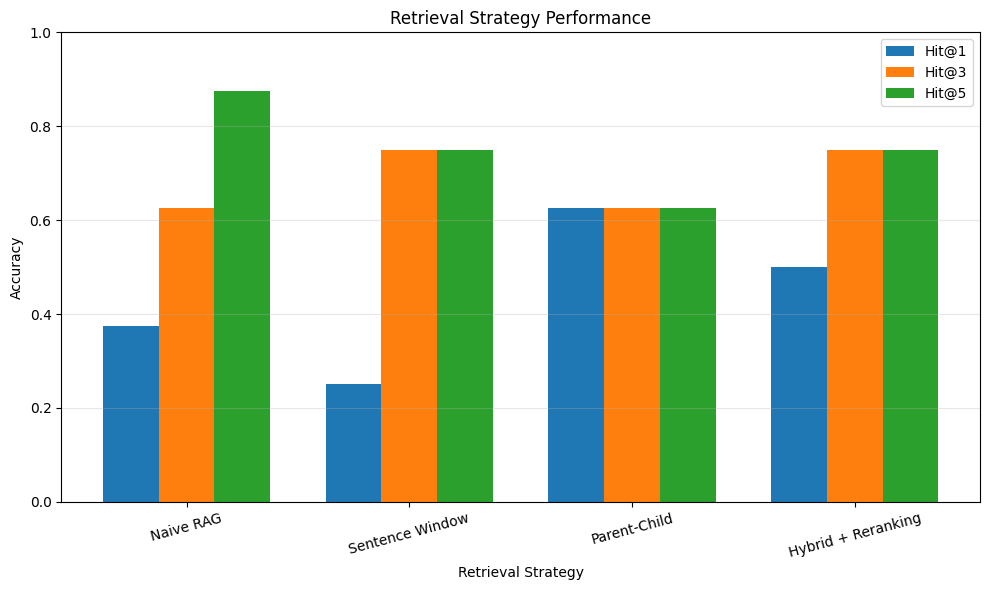

In [66]:
import matplotlib.pyplot as plt

x = np.arange(len(comparison_df))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(x - width, comparison_df["Hit@1"], width, label="Hit@1")
plt.bar(x, comparison_df["Hit@3"], width, label="Hit@3")
plt.bar(x + width, comparison_df["Hit@5"], width, label="Hit@5")

plt.xticks(x, comparison_df["Strategy"], rotation=15)
plt.ylabel("Accuracy")
plt.xlabel("Retrieval Strategy")
plt.title("Retrieval Strategy Performance")
plt.ylim(0, 1.0)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [67]:
comparison_df.to_csv(
    "../data/hybrid_retrieval_evaluation.csv",
    index=False
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.


In [68]:
def evaluate_fused_results(evaluation_results, ground_truth):
    rows = []

    for query, results in evaluation_results.items():
        fused = results["fused"]

        sections = [
            canonicalize_section(
                r.get("metadata", {}).get("section", "N/A")
            )
            for r in fused
        ]

        expected = ground_truth[query]

        rows.append({
            "Query": query,
            "Expected": expected,
            "Hit@1": expected in sections[:1],
            "Hit@3": expected in sections[:3],
            "Hit@5": expected in sections[:5]
        })

    df = pd.DataFrame(rows)

    return {
        "details": df,
        "Hit@1": df["Hit@1"].mean(),
        "Hit@3": df["Hit@3"].mean(),
        "Hit@5": df["Hit@5"].mean()
    }


fused_eval = evaluate_fused_results(
    evaluation_results,
    ground_truth_sections
)

print("RRF Fusion vs Hybrid + Reranking")
print("=" * 60)

print(
    f"RRF Fusion          → "
    f"Hit@1: {fused_eval['Hit@1']:.3f}, "
    f"Hit@3: {fused_eval['Hit@3']:.3f}, "
    f"Hit@5: {fused_eval['Hit@5']:.3f}"
)

print(
    f"Hybrid + Reranking  → "
    f"Hit@1: {hit_at_1:.3f}, "
    f"Hit@3: {hit_at_3:.3f}, "
    f"Hit@5: {hit_at_5:.3f}"
)

RRF Fusion vs Hybrid + Reranking
RRF Fusion          → Hit@1: 0.625, Hit@3: 0.625, Hit@5: 0.750
Hybrid + Reranking  → Hit@1: 0.500, Hit@3: 0.750, Hit@5: 0.750


In [69]:
# Cell 66 — Final Evaluation Comparison

final_comparison = pd.DataFrame({
    "Strategy": [
        "Naive RAG",
        "Sentence Window",
        "Parent-Child",
        "RRF Fusion",
        "Hybrid + Reranking"
    ],
    "Hit@1": [
        naive_eval["Hit@1"],
        sentence_window_eval["Hit@1"],
        parent_child_eval["Hit@1"],
        fused_eval["Hit@1"],
        hit_at_1
    ],
    "Hit@3": [
        naive_eval["Hit@3"],
        sentence_window_eval["Hit@3"],
        parent_child_eval["Hit@3"],
        fused_eval["Hit@3"],
        hit_at_3
    ],
    "Hit@5": [
        naive_eval["Hit@5"],
        sentence_window_eval["Hit@5"],
        parent_child_eval["Hit@5"],
        fused_eval["Hit@5"],
        hit_at_5
    ]
})

print("Final Retrieval Evaluation")
print("=" * 70)

display(final_comparison)

Final Retrieval Evaluation


,Strategy,Hit@1,Hit@3,Hit@5
0,Naive RAG,0.375,0.625,0.875
1,Sentence Window,0.250,0.750,0.750
2,Parent-Child,0.625,0.625,0.625
3,RRF Fusion,0.625,0.625,0.750
4,Hybrid + Reranking,0.500,0.750,0.750


In [70]:
# Cell 67 — Save Final Retrieval Evaluation

FINAL_EVALUATION_PATH = "../data/final_retrieval_evaluation.csv"

final_comparison.to_csv(
    FINAL_EVALUATION_PATH,
    index=False
)

print(f"Final evaluation saved to: {FINAL_EVALUATION_PATH}")

Final evaluation saved to: ../data/final_retrieval_evaluation.csv


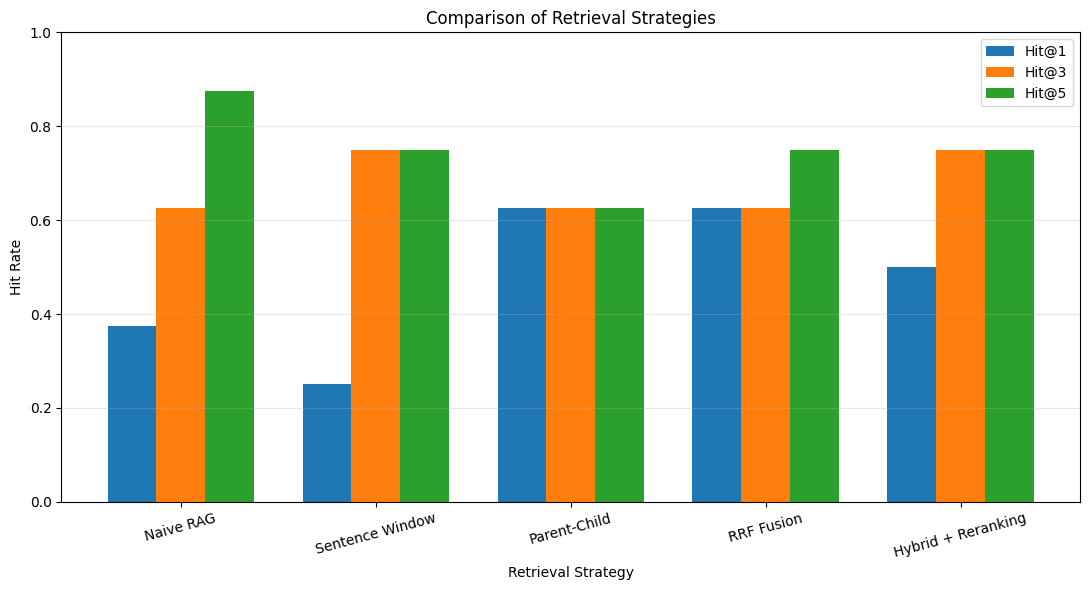

In [71]:
# Cell 68 — Final Retrieval Strategy Comparison

x = np.arange(len(final_comparison))
width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    final_comparison["Hit@1"],
    width,
    label="Hit@1"
)

plt.bar(
    x,
    final_comparison["Hit@3"],
    width,
    label="Hit@3"
)

plt.bar(
    x + width,
    final_comparison["Hit@5"],
    width,
    label="Hit@5"
)

plt.xticks(
    x,
    final_comparison["Strategy"],
    rotation=15
)

plt.xlabel("Retrieval Strategy")
plt.ylabel("Hit Rate")
plt.title("Comparison of Retrieval Strategies")
plt.ylim(0, 1.0)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [72]:
# Cell 69 — Inspect Ground-Truth Chunks

target_sections = [
    "eligibility",
    "benefits",
    "documents_required",
    "application_process",
    "details",
    "frequently_asked_questions"
]

for section in target_sections:
    print("\n" + "=" * 100)
    print(f"SECTION: {section}")
    print("=" * 100)

    found = False

    for metadata in naive_metadata:
        if canonicalize_section(
            metadata.get("section", "")
        ) == section:
            print("\n--- Naive RAG ---")
            print(metadata.get("text", "")[:1500])
            found = True

    for metadata in sentence_window_metadata:
        if canonicalize_section(
            metadata.get("section", "")
        ) == section:
            print("\n--- Sentence Window ---")
            print(
                metadata.get(
                    "window_text",
                    metadata.get("text", "")
                )[:1500]
            )
            found = True
            break

    for metadata in parent_child_metadata:
        if canonicalize_section(
            metadata.get("section", "")
        ) == section:
            print("\n--- Parent-Child ---")
            print(
                metadata.get(
                    "child_text",
                    metadata.get(
                        "text",
                        metadata.get("parent_text", "")
                    )
                )[:1500]
            )
            found = True
            break

    if not found:
        print("No content found.")


SECTION: eligibility

--- Naive RAG ---
1. Income Category

The family should fall under the applicable income category specified under the scheme, including:

- Economically Weaker Section (EWS)
- Low Income Group (LIG)
- Middle Income Group I (MIG-I)
- Middle Income Group II (MIG-II)

2. Ownership of Pucca House

The beneficiary family should not own a pucca house anywhere in India.

3. Definition of Family

The beneficiary family consists of the husband, wife and unmarried children.

4. Location

The beneficiary should belong to a town or city covered under the scheme.

5. Previous Government Housing Benefits

The beneficiary family should not have previously availed benefits under any housing-related scheme of the Government of India, as applicable under the scheme.

--- Sentence Window ---
1. Income Category The family should fall under the applicable income category specified under the scheme, including: - Economically Weaker Section (EWS) - Low Income Group (LIG) - Middle Incom

In [73]:
# Cell 69 — Create Section-Aware Text

def add_section_context(text, metadata):
    section = metadata.get("section", "")
    
    if section:
        section = str(section).replace("_", " ").title()
        return f"Section: {section}\n\n{text}"
    
    return text


# Test on the important sections
test_sections = [
    "eligibility",
    "benefits",
    "documents_required",
    "application_process"
]

for section in test_sections:
    print("\n" + "=" * 80)
    print(f"SECTION: {section}")
    print("=" * 80)

    for metadata in naive_metadata:
        if canonicalize_section(metadata.get("section", "")) == section:
            section_aware_text = add_section_context(
                metadata["text"],
                metadata
            )

            print(section_aware_text[:800])
            break


SECTION: eligibility
Section: Eligibility

1. Income Category

The family should fall under the applicable income category specified under the scheme, including:

- Economically Weaker Section (EWS)
- Low Income Group (LIG)
- Middle Income Group I (MIG-I)
- Middle Income Group II (MIG-II)

2. Ownership of Pucca House

The beneficiary family should not own a pucca house anywhere in India.

3. Definition of Family

The beneficiary family consists of the husband, wife and unmarried children.

4. Location

The beneficiary should belong to a town or city covered under the scheme.

5. Previous Government Housing Benefits

The beneficiary family should not have previously availed benefits under any housing-related scheme of the Government of India, as applicable under the scheme.

SECTION: benefits
Section: Benefits

1. Slum Rehabilitation

Slum dwellers are provided houses using land as a resource with the participation of private developers wherever applicable.

2. Credit Linked Subsidy Sc

In [74]:
# Cell 70 — Test Section-Aware Naive Retrieval

import faiss

# Create section-aware texts
section_aware_texts = [
    add_section_context(
        metadata["text"],
        metadata
    )
    for metadata in naive_metadata
]

# Generate embeddings
section_aware_embeddings = embedding_model.encode(
    section_aware_texts,
    normalize_embeddings=True
)

section_aware_embeddings = np.asarray(
    section_aware_embeddings,
    dtype="float32"
)

# Create temporary FAISS index
section_aware_index = faiss.IndexFlatIP(
    section_aware_embeddings.shape[1]
)

section_aware_index.add(section_aware_embeddings)


# Test query
test_query = "Who is eligible for PMAY-U?"

query_embedding = embedding_model.encode(
    [test_query],
    normalize_embeddings=True
)

query_embedding = np.asarray(
    query_embedding,
    dtype="float32"
)

scores, indices = section_aware_index.search(
    query_embedding,
    5
)


print("=" * 80)
print(f"SECTION-AWARE RETRIEVAL: {test_query}")
print("=" * 80)

for rank, (score, idx) in enumerate(
    zip(scores[0], indices[0]),
    start=1
):
    metadata = naive_metadata[idx]

    print(f"\nRank {rank}")
    print(f"Section : {metadata.get('section')}")
    print(f"Score   : {score:.4f}")
    print(f"Text    : {metadata['text'][:300]}")

SECTION-AWARE RETRIEVAL: Who is eligible for PMAY-U?

Rank 1
Section : application_process
Score   : 0.6755
Text    : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

2. Applications may be submitted through the online system or through the concerned Urban Local Body (ULB) or other designated agencies.

3. The applicant must provide the required 

Rank 2
Section : details
Score   : 0.5537
Text    : Pradhan Mantri Awas Yojana - Urban (PMAY-U) is a scheme of the Ministry of Housing & Urban Affairs (MoHUA), Government of India.

The scheme was launched to address the urban housing shortage among economically weaker sections (EWS), low income groups (LIG), middle income groups (MIG), including slu

Rank 3
Section : documents_required
Score   : 0.4129
Text    : 1. Aadhaar Card / Aadhaar Number or Virtual ID, wherever applicable.

2. Identity proof.

3. Address proof.

4. Income certificate / income-related details.

5. Ba

In [75]:
# Cell 71 — Test Query Expansion

query_expansions = {
    "Who is eligible for PMAY-U?":
        "Who is eligible for PMAY-U? PMAY-U eligibility criteria income category beneficiary requirements",

    "What are the benefits of PMAY-U?":
        "What are the benefits of PMAY-U? PMAY-U benefits housing assistance subsidy slum rehabilitation affordable housing",

    "What documents are required to apply for PMAY-U?":
        "What documents are required to apply for PMAY-U? required documents Aadhaar identity address income bank account",

    "What are the income categories under PMAY-U?":
        "What are the income categories under PMAY-U? EWS LIG MIG-I MIG-II eligibility income category"
}


def test_expanded_query(query):
    expanded_query = query_expansions.get(query, query)

    query_embedding = embedding_model.encode(
        [expanded_query],
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding,
        dtype="float32"
    )

    scores, indices = naive_index.search(
        query_embedding,
        5
    )

    print("=" * 80)
    print(f"Original Query : {query}")
    print(f"Expanded Query : {expanded_query}")
    print("=" * 80)

    for rank, (score, idx) in enumerate(
        zip(scores[0], indices[0]),
        start=1
    ):
        metadata = naive_metadata[idx]

        print(
            f"Rank {rank} | "
            f"Section: {metadata.get('section')} | "
            f"Score: {score:.4f}"
        )


for query in query_expansions:
    test_expanded_query(query)

Original Query : Who is eligible for PMAY-U?
Expanded Query : Who is eligible for PMAY-U? PMAY-U eligibility criteria income category beneficiary requirements
Rank 1 | Section: application_process | Score: 0.8250
Rank 2 | Section: details | Score: 0.5628
Rank 3 | Section: eligibility | Score: 0.4795
Rank 4 | Section: documents_required | Score: 0.4379
Rank 5 | Section: benefits | Score: 0.4237
Original Query : What are the benefits of PMAY-U?
Expanded Query : What are the benefits of PMAY-U? PMAY-U benefits housing assistance subsidy slum rehabilitation affordable housing
Rank 1 | Section: details | Score: 0.5995
Rank 2 | Section: benefits | Score: 0.5488
Rank 3 | Section: application_process | Score: 0.5301
Rank 4 | Section: documents_required | Score: 0.3753
Rank 5 | Section: eligibility | Score: 0.3388
Original Query : What documents are required to apply for PMAY-U?
Expanded Query : What documents are required to apply for PMAY-U? required documents Aadhaar identity address income 

In [76]:
%pip install rank-bm25

Note: you may need to restart the kernel to use updated packages.


In [77]:
# Cell 73 — BM25 Retriever

from rank_bm25 import BM25Okapi
import re


def tokenize_text(text):
    """
    Simple tokenizer for BM25.
    Converts text to lowercase and keeps words/numbers.
    """
    return re.findall(r"\b[a-zA-Z0-9]+(?:-[a-zA-Z0-9]+)?\b", text.lower())


# Use the existing Naive RAG chunks
bm25_documents = [
    metadata["text"]
    for metadata in naive_metadata
]

# Tokenize documents
bm25_tokenized_documents = [
    tokenize_text(text)
    for text in bm25_documents
]

# Build BM25 index
bm25 = BM25Okapi(bm25_tokenized_documents)

print("BM25 index created successfully.")
print(f"Number of documents: {len(bm25_documents)}")

BM25 index created successfully.
Number of documents: 5


In [78]:
# Cell 74 — Test BM25 Retrieval

def retrieve_bm25(query, top_k=5):
    query_tokens = tokenize_text(query)

    scores = bm25.get_scores(query_tokens)

    top_indices = np.argsort(scores)[::-1][:top_k]

    results = []

    for rank, idx in enumerate(top_indices, start=1):
        metadata = naive_metadata[idx]

        results.append(
            create_retrieval_result(
                text=metadata["text"],
                score=scores[idx],
                rank=rank,
                source="bm25",
                metadata=metadata
            )
        )

    return results


# Test query
test_query = "Who is eligible for PMAY-U?"

bm25_results = retrieve_bm25(test_query, top_k=5)

display_results(
    bm25_results,
    title=f"BM25 Results — {test_query}"
)

BM25 Results — Who is eligible for PMAY-U?

Rank 1
Original Score: 0.864653
Source        : bm25
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

2. Applications may be submitted through the online system or through the concerned Urban Local Body (ULB) or other designated agencies.

3. The applicant must provide the required personal, family, income and other details along with the necessary documents.

4. The application is verified by the concerned authorities before the beneficiary is considered for assistance under th

Rank 2
Original Score: 0.688690
Source        : bm25
Text          : 1. Slum Rehabilitation

Slum dwellers are provided houses using land as a resource with the participation of private developers wherever applicable.

2. Credit Linked Subsidy Scheme (CLSS)

Interest subsidy is provided on housing loans to eligible beneficiaries belonging to specified income categories.

The scheme 

In [79]:
# Cell 75 — Create Metadata-Enriched Retrieval Text

section_keywords = {
    "eligibility": [
        "eligible",
        "eligibility",
        "eligibility criteria",
        "income category",
        "EWS",
        "LIG",
        "MIG-I",
        "MIG-II",
        "pucca house",
        "beneficiary",
        "beneficiary family"
    ],
    
    "benefits": [
        "benefits",
        "housing assistance",
        "housing subsidy",
        "slum rehabilitation",
        "credit linked subsidy",
        "CLSS",
        "affordable housing",
        "AHP",
        "beneficiary-led construction",
        "BLC"
    ],
    
    "documents_required": [
        "documents",
        "required documents",
        "Aadhaar",
        "identity proof",
        "address proof",
        "income certificate",
        "bank account",
        "mobile number",
        "family details"
    ],
    
    "application_process": [
        "application",
        "apply",
        "application process",
        "online application",
        "Urban Local Body",
        "ULB",
        "verification"
    ],
    
    "details": [
        "PMAY-U",
        "Pradhan Mantri Awas Yojana Urban",
        "scheme",
        "Ministry of Housing",
        "urban housing",
        "housing shortage"
    ]
}


def create_enriched_text(metadata):
    section = canonicalize_section(
        metadata.get("section", "")
    )

    text = metadata.get("text", "")

    keywords = section_keywords.get(section, [])

    keyword_text = ", ".join(keywords)

    return (
        f"Section: {section.replace('_', ' ').title()}\n"
        f"Keywords: {keyword_text}\n\n"
        f"{text}"
    )


# Create enriched documents
enriched_documents = [
    create_enriched_text(metadata)
    for metadata in naive_metadata
]


# Display them
for metadata, enriched_text in zip(
    naive_metadata,
    enriched_documents
):
    print("\n" + "=" * 80)
    print(f"SECTION: {metadata.get('section')}")
    print("=" * 80)
    print(enriched_text[:1000])


SECTION: details
Section: Details
Keywords: PMAY-U, Pradhan Mantri Awas Yojana Urban, scheme, Ministry of Housing, urban housing, housing shortage

Pradhan Mantri Awas Yojana - Urban (PMAY-U) is a scheme of the Ministry of Housing & Urban Affairs (MoHUA), Government of India.

The scheme was launched to address the urban housing shortage among economically weaker sections (EWS), low income groups (LIG), middle income groups (MIG), including slum dwellers, by ensuring a pucca house to eligible urban households.

The scheme covers statutory towns as per Census 2011 and towns subsequently notified. It also provides support for affordable housing and improvement of housing conditions in urban areas.

The scheme includes provisions related to slum rehabilitation, affordable housing, credit linked subsidy and beneficiary-led individual house construction or enhancement.

Aadhaar or Virtual ID may be required for beneficiaries under the scheme.

The mission aims to provide affordable and ade

In [80]:
# Cell 76 — Test BM25 with Enriched Documents

# Tokenize enriched documents
enriched_tokenized_documents = [
    tokenize_text(text)
    for text in enriched_documents
]

# Build temporary BM25 index
enriched_bm25 = BM25Okapi(
    enriched_tokenized_documents
)


def retrieve_enriched_bm25(query, top_k=5):
    query_tokens = tokenize_text(query)

    scores = enriched_bm25.get_scores(query_tokens)

    top_indices = np.argsort(scores)[::-1][:top_k]

    results = []

    for rank, idx in enumerate(top_indices, start=1):
        metadata = naive_metadata[idx]

        results.append(
            create_retrieval_result(
                text=metadata["text"],
                score=scores[idx],
                rank=rank,
                source="enriched_bm25",
                metadata=metadata
            )
        )

    return results


# Test the important queries
test_queries = [
    "Who is eligible for PMAY-U?",
    "What are the benefits of PMAY-U?",
    "What documents are required to apply for PMAY-U?",
    "What are the income categories under PMAY-U?"
]


for query in test_queries:

    print("\n" + "=" * 80)
    print(f"QUERY: {query}")
    print("=" * 80)

    results = retrieve_enriched_bm25(query, top_k=5)

    for rank, result in enumerate(results, start=1):
        section = canonicalize_section(
            result["metadata"].get("section", "")
        )

        print(
            f"Rank {rank} | "
            f"Section: {section:<25} | "
            f"Score: {result['score']:.4f}"
        )


QUERY: Who is eligible for PMAY-U?
Rank 1 | Section: application_process       | Score: 0.8115
Rank 2 | Section: details                   | Score: 0.6923
Rank 3 | Section: benefits                  | Score: 0.6479
Rank 4 | Section: documents_required        | Score: 0.1490
Rank 5 | Section: eligibility               | Score: 0.1370

QUERY: What are the benefits of PMAY-U?
Rank 1 | Section: benefits                  | Score: 2.4369
Rank 2 | Section: eligibility               | Score: 1.0476
Rank 3 | Section: details                   | Score: 0.7313
Rank 4 | Section: application_process       | Score: 0.6926
Rank 5 | Section: documents_required        | Score: 0.6334

QUERY: What documents are required to apply for PMAY-U?
Rank 1 | Section: application_process       | Score: 2.6672
Rank 2 | Section: benefits                  | Score: 1.9321
Rank 3 | Section: documents_required        | Score: 1.2458
Rank 4 | Section: details                   | Score: 0.7654
Rank 5 | Section: eligibil

In [81]:
# Cell 77 — Compare Query Similarity Across Sections

def calculate_section_similarities(query, documents):
    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )

    document_embeddings = embedding_model.encode(
        documents,
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding,
        dtype="float32"
    )

    document_embeddings = np.asarray(
        document_embeddings,
        dtype="float32"
    )

    similarities = np.dot(
        document_embeddings,
        query_embedding[0]
    )

    return similarities


section_aware_documents = [
    add_section_context(
        metadata["text"],
        metadata
    )
    for metadata in naive_metadata
]

query = "Who is eligible for PMAY-U?"

similarities = calculate_section_similarities(
    query,
    section_aware_documents
)

section_similarity_df = pd.DataFrame({
    "Section": [
        canonicalize_section(metadata["section"])
        for metadata in naive_metadata
    ],
    "Similarity": similarities
})

section_similarity_df = section_similarity_df.sort_values(
    "Similarity",
    ascending=False
).reset_index(drop=True)

print(f"Query: {query}")
print("=" * 60)

section_similarity_df

Query: Who is eligible for PMAY-U?


,Section,Similarity
0,application_process,0.675460
1,details,0.553679
2,documents_required,0.412940
3,eligibility,0.323248
4,benefits,0.317440


In [82]:
# Cell 78 — Test a Stronger Embedding Model

from sentence_transformers import SentenceTransformer

BGE_MODEL_NAME = "BAAI/bge-base-en-v1.5"

bge_model = SentenceTransformer(BGE_MODEL_NAME)

print("BGE embedding model loaded successfully.")
print(f"Model: {BGE_MODEL_NAME}")

c:\Users\Dell\anaconda3\envs\asl_env\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Dell\.cache\huggingface\hub\models--BAAI--bge-base-en-v1.5. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Dell\anaconda3\envs\asl_env\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `hugg

BGE embedding model loaded successfully.
Model: BAAI/bge-base-en-v1.5


In [83]:
# Cell 79 — BGE Similarity Test

bge_embeddings = bge_model.encode(
    section_aware_documents,
    normalize_embeddings=True
)

bge_query_embedding = bge_model.encode(
    ["Who is eligible for PMAY-U?"],
    normalize_embeddings=True
)

bge_embeddings = np.asarray(
    bge_embeddings,
    dtype="float32"
)

bge_query_embedding = np.asarray(
    bge_query_embedding,
    dtype="float32"
)

bge_similarities = np.dot(
    bge_embeddings,
    bge_query_embedding[0]
)

bge_similarity_df = pd.DataFrame({
    "Section": [
        canonicalize_section(metadata["section"])
        for metadata in naive_metadata
    ],
    "Similarity": bge_similarities
})

bge_similarity_df = bge_similarity_df.sort_values(
    "Similarity",
    ascending=False
).reset_index(drop=True)

print("BGE Embedding Similarity")
print("=" * 60)

bge_similarity_df

BGE Embedding Similarity


,Section,Similarity
0,application_process,0.803897
1,details,0.722930
2,documents_required,0.684293
3,eligibility,0.620820
4,benefits,0.497069


In [84]:
# Cell 80 — Generic BM25 Corpus

def get_retrieval_text(metadata, retrieval_type):
    """
    Extract text from different retrieval strategies
    without assuming any particular document or domain.
    """

    if retrieval_type == "naive":
        return metadata.get("text", "")

    elif retrieval_type == "sentence_window":
        return metadata.get(
            "window_text",
            metadata.get("text", "")
        )

    elif retrieval_type == "parent_child":
        return metadata.get(
            "child_text",
            metadata.get(
                "text",
                metadata.get("parent_text", "")
            )
        )

    return ""


# Build a generic corpus from all three retrieval stores
bm25_corpus = []
bm25_metadata = []

corpora = [
    (naive_metadata, "naive"),
    (sentence_window_metadata, "sentence_window"),
    (parent_child_metadata, "parent_child")
]

for metadata_list, source in corpora:

    for metadata in metadata_list:

        text = get_retrieval_text(
            metadata,
            source
        ).strip()

        if not text:
            continue

        bm25_corpus.append(text)

        bm25_metadata.append({
            "source": source,
            "metadata": metadata
        })


print("Generic BM25 corpus created")
print("=" * 60)
print(f"Total documents/chunks: {len(bm25_corpus)}")

Generic BM25 corpus created
Total documents/chunks: 148


In [85]:
# Cell 81 — Generic BM25 Index

bm25_tokenized_corpus = [
    tokenize_text(text)
    for text in bm25_corpus
]

bm25 = BM25Okapi(
    bm25_tokenized_corpus
)

print("Generic BM25 index created successfully.")
print(f"Indexed chunks: {len(bm25_corpus)}")

Generic BM25 index created successfully.
Indexed chunks: 148


In [86]:
# Cell 82 — Generic BM25 Retrieval

def retrieve_bm25_generic(query, top_k=10):

    query_tokens = tokenize_text(query)

    scores = bm25.get_scores(query_tokens)

    top_indices = np.argsort(scores)[::-1][:top_k]

    results = []

    for rank, idx in enumerate(top_indices, start=1):

        corpus_metadata = bm25_metadata[idx]

        metadata = corpus_metadata["metadata"]
        source = corpus_metadata["source"]

        results.append(
            create_retrieval_result(
                text=bm25_corpus[idx],
                score=scores[idx],
                rank=rank,
                source=f"bm25_{source}",
                metadata=metadata
            )
        )

    return results

In [87]:
# Cell 83 — Test Generic BM25 Retrieval

test_queries = [
    "Who is eligible for PMAY-U?",
    "What are the benefits of PMAY-U?",
    "What documents are required to apply for PMAY-U?",
    "How can I apply for PMAY-U?"
]

for query in test_queries:

    print("\n" + "=" * 90)
    print(f"QUERY: {query}")
    print("=" * 90)

    results = retrieve_bm25_generic(
        query,
        top_k=5
    )

    for rank, result in enumerate(results, start=1):

        section = canonicalize_section(
            result.get("metadata", {}).get("section", "N/A")
        )

        print(
            f"Rank {rank} | "
            f"Source: {result['source']:<25} | "
            f"Section: {section:<30} | "
            f"Score: {result['score']:.4f}"
        )


QUERY: Who is eligible for PMAY-U?
Rank 1 | Source: bm25_sentence_window      | Section: application_process            | Score: 4.6235
Rank 2 | Source: bm25_parent_child         | Section: application_process            | Score: 4.5520
Rank 3 | Source: bm25_sentence_window      | Section: application_process            | Score: 4.5520
Rank 4 | Source: bm25_parent_child         | Section: application_process            | Score: 4.5437
Rank 5 | Source: bm25_sentence_window      | Section: application_process            | Score: 4.5437

QUERY: What are the benefits of PMAY-U?
Rank 1 | Source: bm25_sentence_window      | Section: frequently_asked_questions     | Score: 10.7428
Rank 2 | Source: bm25_parent_child         | Section: frequently_asked_questions     | Score: 7.8900
Rank 3 | Source: bm25_sentence_window      | Section: frequently_asked_questions     | Score: 7.8900
Rank 4 | Source: bm25_sentence_window      | Section: frequently_asked_questions     | Score: 7.8900
Rank 5 | Sour

In [88]:
# Cell 84 — BM25 over Base Document Chunks

bm25_corpus = [
    metadata.get("text", "").strip()
    for metadata in naive_metadata
]

bm25_metadata = [
    {
        "source": "bm25",
        "metadata": metadata
    }
    for metadata in naive_metadata
    if metadata.get("text", "").strip()
]

# Remove empty documents
valid_pairs = [
    (text, metadata)
    for text, metadata in zip(
        bm25_corpus,
        bm25_metadata
    )
    if text
]

bm25_corpus = [
    pair[0]
    for pair in valid_pairs
]

bm25_metadata = [
    pair[1]
    for pair in valid_pairs
]

# Tokenize
bm25_tokenized_corpus = [
    tokenize_text(text)
    for text in bm25_corpus
]

# Build BM25
bm25 = BM25Okapi(
    bm25_tokenized_corpus
)

print("BM25 index rebuilt successfully.")
print(f"Indexed base chunks: {len(bm25_corpus)}")

BM25 index rebuilt successfully.
Indexed base chunks: 5


In [89]:
def retrieve_bm25_generic(query, top_k=5):

    query_tokens = tokenize_text(query)

    scores = bm25.get_scores(query_tokens)

    top_indices = np.argsort(scores)[::-1][:top_k]

    results = []

    for rank, idx in enumerate(top_indices, start=1):

        metadata = bm25_metadata[idx]["metadata"]

        results.append(
            create_retrieval_result(
                text=bm25_corpus[idx],
                score=scores[idx],
                rank=rank,
                source="bm25",
                metadata=metadata
            )
        )

    return results

In [90]:
# Cell 85 — Test Base-Chunk BM25

test_queries = [
    "Who is eligible for PMAY-U?",
    "What are the benefits of PMAY-U?",
    "What documents are required to apply for PMAY-U?",
    "How can I apply for PMAY-U?",
    "What are the income categories under PMAY-U?"
]

for query in test_queries:

    print("\n" + "=" * 90)
    print(f"QUERY: {query}")
    print("=" * 90)

    results = retrieve_bm25_generic(
        query,
        top_k=5
    )

    for rank, result in enumerate(results, start=1):

        section = canonicalize_section(
            result.get("metadata", {}).get("section", "N/A")
        )

        print(
            f"Rank {rank} | "
            f"Section: {section:<30} | "
            f"Score: {result['score']:.4f}"
        )


QUERY: Who is eligible for PMAY-U?
Rank 1 | Section: application_process            | Score: 0.8647
Rank 2 | Section: benefits                       | Score: 0.6887
Rank 3 | Section: details                        | Score: 0.6597
Rank 4 | Section: documents_required             | Score: 0.1611
Rank 5 | Section: eligibility                    | Score: 0.0000

QUERY: What are the benefits of PMAY-U?
Rank 1 | Section: eligibility                    | Score: 2.1427
Rank 2 | Section: benefits                       | Score: 1.9971
Rank 3 | Section: application_process            | Score: 0.7370
Rank 4 | Section: details                        | Score: 0.6883
Rank 5 | Section: documents_required             | Score: 0.6804

QUERY: What documents are required to apply for PMAY-U?
Rank 1 | Section: application_process            | Score: 2.2467
Rank 2 | Section: benefits                       | Score: 1.9611
Rank 3 | Section: documents_required             | Score: 1.1313
Rank 4 | Section: det

In [91]:
# Cell 86 — Four-Way Hybrid Fusion Test

test_query = "Who is eligible for PMAY-U?"

# Dense retrieval
naive_results = retrieve_naive(
    test_query,
    top_k=10
)

sentence_window_results = retrieve_sentence_window(
    test_query,
    top_k=10
)

parent_child_results = retrieve_parent_child(
    test_query,
    top_k=10
)

# Lexical retrieval
bm25_results = retrieve_bm25_generic(
    test_query,
    top_k=10
)

# Four retrieval signals
retrieval_sources = [
    naive_results,
    sentence_window_results,
    parent_child_results,
    bm25_results
]

# RRF fusion
four_way_fused = reciprocal_rank_fusion(
    retrieval_sources,
    k=RRF_K
)

# Keep a larger candidate pool
four_way_fused = four_way_fused[:20]

display_results(
    four_way_fused,
    title="Four-Way Hybrid RRF"
)

Four-Way Hybrid RRF

Rank 1
RRF Score     : 0.032787
Original Score: 0.696832
Source        : naive
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

2. Applications may be submitted through the online system or through the concerned Urban Local Body (ULB) or other designated agencies.

3. The applicant must provide the required personal, family, income and other details along with the necessary documents.

4. The application is verified by the concerned authorities before the beneficiary is considered for assistance under th

Rank 2
RRF Score     : 0.032522
Original Score: 0.744815
Source        : sentence_window
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government. 2.

Rank 3
RRF Score     : 0.032002
Original Score: 0.553095
Source        : naive
Text          : Pradhan Mantri Awas Yojana - Urban (PMAY-U) is a scheme of t

In [92]:
# Cell 87 — Analyze RRF Candidate Diversity

from collections import Counter

section_counts = Counter()

for result in four_way_fused:
    section = canonicalize_section(
        result.get("metadata", {}).get("section", "unknown")
    )

    section_counts[section] += 1


print("Candidate Distribution After RRF")
print("=" * 60)

for section, count in section_counts.most_common():
    print(f"{section:<35} : {count}")

Candidate Distribution After RRF
frequently_asked_questions          : 8
application_process                 : 6
details                             : 2
documents_required                  : 2
benefits                            : 1
eligibility                         : 1


In [93]:
# Cell 88 — Inspect Metadata Identity

sample_sources = [
    ("naive", naive_metadata),
    ("sentence_window", sentence_window_metadata),
    ("parent_child", parent_child_metadata)
]

for source_name, metadata_list in sample_sources:
    print("\n" + "=" * 80)
    print(f"SOURCE: {source_name}")
    print("=" * 80)

    for i, metadata in enumerate(metadata_list[:5]):
        print(f"\nItem {i}:")
        print(metadata)


SOURCE: naive

Item 0:
{'chunk_id': 'naive_0', 'scheme': 'Pradhan Mantri Awas Yojana - Urban', 'section': 'details', 'text': 'Pradhan Mantri Awas Yojana - Urban (PMAY-U) is a scheme of the Ministry of Housing & Urban Affairs (MoHUA), Government of India.\n\nThe scheme was launched to address the urban housing shortage among economically weaker sections (EWS), low income groups (LIG), middle income groups (MIG), including slum dwellers, by ensuring a pucca house to eligible urban households.\n\nThe scheme covers statutory towns as per Census 2011 and towns subsequently notified. It also provides support for affordable housing and improvement of housing conditions in urban areas.\n\nThe scheme includes provisions related to slum rehabilitation, affordable housing, credit linked subsidy and beneficiary-led individual house construction or enhancement.\n\nAadhaar or Virtual ID may be required for beneficiaries under the scheme.\n\nThe mission aims to provide affordable and adequate housin

In [94]:
# Cell 89 — Create Generic Canonical Document Identity

import hashlib


def get_canonical_id(result):
    """
    Create a generic identity for a retrieved piece of content.

    The identity is based on normalized text, so overlapping
    representations of the same content can be recognized.
    """

    text = result.get("text", "").strip().lower()

    # Normalize whitespace
    text = " ".join(text.split())

    # Create stable hash
    canonical_id = hashlib.md5(
        text.encode("utf-8")
    ).hexdigest()

    return canonical_id


# Test on the current fused results
for rank, result in enumerate(four_way_fused[:10], start=1):

    canonical_id = get_canonical_id(result)

    print(
        f"Rank {rank} | "
        f"Source: {result.get('source')} | "
        f"Canonical ID: {canonical_id[:12]}"
    )

Rank 1 | Source: naive | Canonical ID: 3a175ce3519d
Rank 2 | Source: sentence_window | Canonical ID: ba713d51ea11
Rank 3 | Source: naive | Canonical ID: 8cdeefd07141
Rank 4 | Source: naive | Canonical ID: 269392af9cf4
Rank 5 | Source: sentence_window | Canonical ID: 3bf99724ce73
Rank 6 | Source: naive | Canonical ID: dca79d52bb61
Rank 7 | Source: naive | Canonical ID: ae8f73f945d9
Rank 8 | Source: sentence_window | Canonical ID: 3802a40a0bc1
Rank 9 | Source: sentence_window | Canonical ID: d115ff344c93
Rank 10 | Source: sentence_window | Canonical ID: 0b64c37782f0


In [95]:
# Cell 90 — Generic Retrieval Identity

def get_retrieval_identity(result):
    """
    Generate a canonical identity for a retrieved result.
    This prevents overlapping representations from receiving
    multiple independent RRF votes.
    """

    metadata = result.get("metadata", {})
    source = result.get("source", "")

    # Naive RAG
    if source == "naive":
        return (
            "naive",
            metadata.get("chunk_id")
        )

    # Sentence Window
    elif source == "sentence_window":
        text = result.get("text", "").strip().lower()
        text = " ".join(text.split())

        return (
            "sentence_window",
            text
        )

    # Parent-Child
    elif source == "parent_child":
        return (
            "parent_child",
            metadata.get("parent_id")
        )

    # BM25
    elif source == "bm25":
        return (
            "bm25",
            metadata.get("chunk_id")
        )

    # Generic fallback
    else:
        return (
            source,
            get_canonical_id(result)
        )


# Test the identities
for rank, result in enumerate(
    four_way_fused[:15],
    start=1
):
    identity = get_retrieval_identity(result)

    print(
        f"Rank {rank} | "
        f"Source: {result.get('source'):<20} | "
        f"Identity: {identity}"
    )

Rank 1 | Source: naive                | Identity: ('naive', 'naive_3')
Rank 2 | Source: sentence_window      | Identity: ('sentence_window', '1. eligible beneficiaries can apply for pmay-u through the applicable application process provided by the government. 2.')
Rank 3 | Source: naive                | Identity: ('naive', 'naive_0')
Rank 4 | Source: naive                | Identity: ('naive', 'naive_1')
Rank 5 | Source: sentence_window      | Identity: ('sentence_window', '4. will i still be eligible to apply for government’s ongoing or upcoming schemes if i apply for pmay-u? the benefits of all existing and future rural schemes will not be denied to a beneficiary solely on the grounds that she/he has availed a house under pmay(u).')
Rank 6 | Source: naive                | Identity: ('naive', 'naive_4')
Rank 7 | Source: naive                | Identity: ('naive', 'naive_2')
Rank 8 | Source: sentence_window      | Identity: ('sentence_window', '4. the application is verified by the conce

In [96]:
def deduplicate_by_identity(results):
    """
    Keep only the highest-ranked result for each retrieval identity.
    Deduplication is performed within a retrieval source.
    """
    seen = set()
    deduplicated = []

    for result in results:
        identity = get_retrieval_identity(result)

        if identity in seen:
            continue

        seen.add(identity)
        deduplicated.append(result)

    return deduplicated

In [97]:
dedup_naive = deduplicate_by_identity(naive_results)
dedup_sentence_window = deduplicate_by_identity(sentence_window_results)
dedup_parent_child = deduplicate_by_identity(parent_child_results)
dedup_bm25 = deduplicate_by_identity(bm25_results)

print("Naive:", len(naive_results), "→", len(dedup_naive))
print("Sentence Window:", len(sentence_window_results), "→", len(dedup_sentence_window))
print("Parent-Child:", len(parent_child_results), "→", len(dedup_parent_child))
print("BM25:", len(bm25_results), "→", len(dedup_bm25))

Naive: 5 → 5
Sentence Window: 10 → 10
Parent-Child: 10 → 4
BM25: 5 → 5


In [98]:
for rank, result in enumerate(dedup_parent_child, start=1):
    print(
        f"Rank {rank} | "
        f"Parent ID: {result['metadata'].get('parent_id')} | "
        f"Text: {result['text'][:200]}"
    )

Rank 1 | Parent ID: 6 | Text: 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government. 2.
Rank 2 | Parent ID: 8 | Text: 4. Will I still be eligible to apply for government’s ongoing or upcoming schemes if I apply for PMAY-U? The benefits of all existing and future rural schemes will not be denied to a beneficiary solel
Rank 3 | Parent ID: 3 | Text: Pradhan Mantri Awas Yojana - Urban (PMAY-U) is a scheme of the Ministry of Housing & Urban Affairs (MoHUA), Government of India. The scheme was launched to address the urban housing shortage among eco
Rank 4 | Parent ID: 7 | Text: Additional documents as required under the applicable component of PMAY-U. 12. Other supporting documents as specified by the concerned authority.


In [99]:
def deduplicated_rrf(retrieval_results, k=60, top_k=10):
    """
    Reciprocal Rank Fusion after removing duplicate identities
    within each retrieval strategy.
    """

    rrf_scores = defaultdict(float)
    document_map = {}

    for results in retrieval_results:

        # Remove duplicates within this retrieval strategy
        results = deduplicate_by_identity(results)

        for rank, document in enumerate(results, start=1):

            identity = get_retrieval_identity(document)

            # Store the first representation
            if identity not in document_map:
                document_map[identity] = document.copy()

            # RRF contribution
            rrf_scores[identity] += 1 / (k + rank)

    fused_results = []

    for identity, score in rrf_scores.items():

        result = document_map[identity].copy()
        result["rrf_score"] = score

        fused_results.append(result)

    fused_results.sort(
        key=lambda x: x["rrf_score"],
        reverse=True
    )

    return fused_results[:top_k]

In [100]:
dedup_fused = deduplicated_rrf(
    [
        naive_results,
        sentence_window_results,
        parent_child_results,
        bm25_results
    ],
    k=RRF_K,
    top_k=15
)

display_results(
    dedup_fused,
    title="Deduplicated Four-Way RRF"
)

Deduplicated Four-Way RRF

Rank 1
RRF Score     : 0.016393
Original Score: 0.696832
Source        : naive
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

2. Applications may be submitted through the online system or through the concerned Urban Local Body (ULB) or other designated agencies.

3. The applicant must provide the required personal, family, income and other details along with the necessary documents.

4. The application is verified by the concerned authorities before the beneficiary is considered for assistance under th

Rank 2
RRF Score     : 0.016393
Original Score: 0.748598
Source        : sentence_window
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

Rank 3
RRF Score     : 0.016393
Original Score: 0.744815
Source        : parent_child
Text          : 1. Eligible beneficiaries can apply for PMAY-U thr

In [101]:
def mmr_diversify(
    query,
    documents,
    top_k=10,
    lambda_mult=0.7
):
    """
    Select diverse candidates using Maximal Marginal Relevance.

    lambda_mult:
        Higher  -> prioritize query relevance
        Lower   -> prioritize diversity
    """

    if not documents:
        return []

    # Embed query and candidate documents
    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )[0]

    document_embeddings = embedding_model.encode(
        [document["text"] for document in documents],
        normalize_embeddings=True
    )

    # Query-document relevance
    relevance_scores = (
        document_embeddings @ query_embedding
    )

    # Document-document similarity
    similarity_matrix = (
        document_embeddings @ document_embeddings.T
    )

    selected_indices = []
    remaining_indices = list(range(len(documents)))

    while remaining_indices and len(selected_indices) < top_k:

        # First document: highest query relevance
        if not selected_indices:
            best_index = max(
                remaining_indices,
                key=lambda i: relevance_scores[i]
            )

        else:
            mmr_scores = {}

            for i in remaining_indices:

                max_similarity = max(
                    similarity_matrix[i][j]
                    for j in selected_indices
                )

                mmr_score = (
                    lambda_mult * relevance_scores[i]
                    - (1 - lambda_mult) * max_similarity
                )

                mmr_scores[i] = mmr_score

            best_index = max(
                mmr_scores,
                key=mmr_scores.get
            )

        selected_indices.append(best_index)
        remaining_indices.remove(best_index)

    return [
        documents[i]
        for i in selected_indices
    ]

In [ ]:
mmr_candidates = mmr_diversify(
    query=test_query,
    documents=dedup_fused,
    top_k=10,
    lambda_mult=0.7
)

display_results(
    mmr_candidates,
    title="MMR-Diversified Candidates"
)

MMR-Diversified Candidates

Rank 1
RRF Score     : 0.016393
Original Score: 0.748598
Source        : sentence_window
Text          : 1. Eligible beneficiaries can apply for PMAY-U through the applicable application process provided by the government.

Rank 2
RRF Score     : 0.015625
Original Score: 0.651913
Source        : sentence_window
Text          : Preference will be given to differently-abled persons, senior citizens, SCs, STs, OBCs, Minority, single women, transgender and other weaker & vulnerable sections of the society. 4. Will I still be eligible to apply for government’s ongoing or upcoming schemes if I apply for PMAY-U?

Rank 3
RRF Score     : 0.015873
Original Score: 0.562176
Source        : parent_child
Text          : Pradhan Mantri Awas Yojana - Urban (PMAY-U) is a scheme of the Ministry of Housing & Urban Affairs (MoHUA), Government of India. The scheme was launched to address the urban housing shortage among economically weaker sections (EWS), low income groups (LIG)

: 